# Proyecto Integrador de Ciencia de Datos — **Fase 3**
## Análisis predictivo: clasificación de inasistencia escolar (EPHC 2022–2025)

| | |
|---|---|
| **Asignatura** | Data Science |
| **Fase** | 3 de 3 — Ponderación 30 % |
| **Integrantes** | Matías Morínigo · César Vielman · Iván Paredes |
| **Target** | `no_asiste` (clasificación binaria desbalanceada) |
| **Partición** | Train 2022–2024 · Test **solo** 2025 (cronológica) |
| **Semilla** | 42 |

**Cómo ejecutar.** Con `output/dataset_fase1.parquet` (generado en Fase 1): `Kernel → Restart & Run All`.


## 1. Correcciones a la Fase 2 y tarea predictiva

No hay devolución escrita del docente en el repositorio. Se mantiene el puente Fase 2 → 3: predictores
`zona`, `departamento`, `edad`, `sexo`, `condicion_actividad`, `pobreza`, `log_ipcm`;
target `no_asiste`; partición cronológica; línea base = clase mayoritaria.

**Tarea:** clasificar si un adolescente no asiste. El motivo declarado **no** es predictor (solo se observa
cuando ya no asiste).


## 2. Carga, features y partición cronológica

In [1]:
import sys, warnings, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay
from sklearn.model_selection import ParameterGrid

SEMILLA, TEST_YEAR = 42, 2025
np.random.seed(SEMILLA)
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')

RAIZ = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(RAIZ))
from src.fase3_helpers import (FEATURE_COLS, TARGET, load_modeling_frame, chronological_split,
                               make_pipeline, metrics_row, best_threshold_by_fbeta, year_folds,
                               fit_temporal_grid, sample_weight_balanced,
                               make_feature_frame, predict_with_models,
                               ZONAS_VALIDAS, SEXOS_VALIDOS, DEPARTAMENTOS_VALIDOS)
THRESHOLD_BETA = 2.0  # prioriza recall

DIR_OUT, DIR_FIG, DIR_TAB, DIR_MOD = RAIZ/'output', RAIZ/'output'/'figuras', RAIZ/'output'/'tablas', RAIZ/'output'/'modelos'
for d in (DIR_FIG, DIR_TAB, DIR_MOD):
    d.mkdir(parents=True, exist_ok=True)

def resolve():
    for p in (DIR_OUT/'dataset_fase1.parquet', RAIZ/'data'/'processed'/'dataset_fase1.parquet'):
        if p.exists() and p.stat().st_size > 0:
            return p
    raise FileNotFoundError('Falta dataset_fase1.parquet')

df = load_modeling_frame(resolve())
train_df, test_df = chronological_split(df, TEST_YEAR)
print(df.shape, 'train', train_df.shape, 'test', test_df.shape)
print('Tasa train', round(train_df[TARGET].mean(), 4), '· tasa test', round(test_df[TARGET].mean(), 4))
train_df.head(3)


(24286, 9) train (18533, 9) test (5753, 9)
Tasa train 0.081 · tasa test 0.0707


,edad,log_ipcm,zona,departamento,sexo,condicion_actividad,pobreza,no_asiste,anio_encuesta
0,13.0,14.412700,Urbana,Capital,Mujer,Inactivo,No pobre,0,2022
1,17.0,14.810473,Urbana,Capital,Hombre,Inactivo,No pobre,0,2022
2,17.0,14.810473,Urbana,Capital,Hombre,Ocupado,No pobre,0,2022


## 3. Selección de hiperparámetros (CV temporal)

Esquema — el **test 2025 no entra** acá:

1. **Train interno:** años anteriores al año de validación (expanding).
2. **Validación:** año siguiente (2023, luego 2024).
3. Se elige la combinación con mayor **F1 media** en esos folds.
4. Después, el umbral se calibra con **F2** en holdout 2024; recién ahí se mide test 2025.


In [2]:
from src.fase3_helpers import fit_temporal_grid, sample_weight_balanced

X_tr, y_tr = train_df[FEATURE_COLS], train_df[TARGET]
X_te, y_te = test_df[FEATURE_COLS], test_df[TARGET]
inner_tr = train_df[train_df.anio_encuesta < 2024]   # calibra umbral
inner_va = train_df[train_df.anio_encuesta == 2024]

print('Folds temporales (solo train 2022–2024):')
for tr_y, va_y in year_folds(sorted(train_df.anio_encuesta.unique())):
    print(f'  train años {list(tr_y)}  →  val {list(va_y)}')

# --- Grillas a explorar (no son el resultado: se buscan abajo) ---
GRIDS = {
    'Logística': {
        'estimator': LogisticRegression(random_state=SEMILLA),
        'grid': {
            'C': [0.1, 1.0, 3.0],
            'class_weight': ['balanced'],
            'max_iter': [500],
            'solver': ['lbfgs'],
        },
        'scale': True,
        'sample_weight': False,
    },
    'Random Forest': {
        'estimator': RandomForestClassifier(random_state=SEMILLA, n_jobs=-1),
        'grid': {
            'n_estimators': [100, 200],
            'max_depth': [6, 10, None],
            'min_samples_leaf': [5, 20],
            'class_weight': ['balanced_subsample'],
        },
        'scale': False,
        'sample_weight': False,
    },
    'HistGradientBoosting': {
        'estimator': HistGradientBoostingClassifier(random_state=SEMILLA),
        'grid': {
            'learning_rate': [0.05, 0.1],
            'max_depth': [3, 5],
            'max_iter': [100, 200],
            'min_samples_leaf': [20, 50],
        },
        'scale': False,
        'sample_weight': True,
    },
}

BEST, CV_F1, CV_TABLES = {}, {}, {}
for nombre, cfg in GRIDS.items():
    n_combos = len(list(ParameterGrid(cfg['grid'])))
    print(f'\n=== {nombre}: explorando {n_combos} combinaciones ===')
    best_params, mean_f1, cv_df = fit_temporal_grid(
        cfg['estimator'], cfg['grid'], train_df,
        scale_numeric=cfg['scale'],
        use_sample_weight=cfg['sample_weight'],
        seed=SEMILLA,
    )
    BEST[nombre] = best_params
    CV_F1[nombre] = mean_f1
    CV_TABLES[nombre] = cv_df
    print('Mejor F1 CV:', round(mean_f1, 4))
    print('Mejores params:', best_params)
    # resumen por combinación
    resumen_cv = (cv_df.groupby('params')[['f1', 'auc']]
                    .mean()
                    .sort_values('f1', ascending=False)
                    .head(5)
                    .round(4))
    display(resumen_cv)
    cv_df.to_csv(DIR_TAB / f'fase3_cv_{nombre.lower().replace(" ", "_")}.csv',
                 index=False, encoding='utf-8-sig')

print('\n>>> Resumen selección por F1 de CV temporal:')
for k, v in sorted(CV_F1.items(), key=lambda kv: -kv[1]):
    print(f'  {k}: F1_CV={v:.4f}  params={BEST[k]}')


Folds temporales (solo train 2022–2024):
  train años [np.int64(2022)]  →  val [np.int64(2023)]
  train años [np.int64(2022), np.int64(2023)]  →  val [np.int64(2024)]

=== Logística: explorando 3 combinaciones ===


Mejor F1 CV: 0.3188
Mejores params: {'C': 0.1, 'class_weight': 'balanced', 'max_iter': 500, 'solver': 'lbfgs'}


,f1,auc
params,,
"{'C': 0.1, 'class_weight': 'balanced', 'max_iter': 500, 'solver': 'lbfgs'}",0.3188,0.8197
"{'C': 1.0, 'class_weight': 'balanced', 'max_iter': 500, 'solver': 'lbfgs'}",0.3177,0.8200
"{'C': 3.0, 'class_weight': 'balanced', 'max_iter': 500, 'solver': 'lbfgs'}",0.3173,0.8200



=== Random Forest: explorando 12 combinaciones ===


Mejor F1 CV: 0.3598
Mejores params: {'class_weight': 'balanced_subsample', 'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 200}


,f1,auc
params,,
"{'class_weight': 'balanced_subsample', 'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 200}",0.3598,0.8200
"{'class_weight': 'balanced_subsample', 'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 100}",0.3591,0.8199
"{'class_weight': 'balanced_subsample', 'max_depth': 10, 'min_samples_leaf': 5, 'n_estimators': 200}",0.3508,0.8262
"{'class_weight': 'balanced_subsample', 'max_depth': 10, 'min_samples_leaf': 5, 'n_estimators': 100}",0.3502,0.8251
"{'class_weight': 'balanced_subsample', 'max_depth': 6, 'min_samples_leaf': 5, 'n_estimators': 200}",0.3352,0.8208



=== HistGradientBoosting: explorando 16 combinaciones ===


Mejor F1 CV: 0.3309
Mejores params: {'learning_rate': 0.1, 'max_depth': 5, 'max_iter': 100, 'min_samples_leaf': 50}


,f1,auc
params,,
"{'learning_rate': 0.1, 'max_depth': 5, 'max_iter': 100, 'min_samples_leaf': 50}",0.3309,0.8212
"{'learning_rate': 0.1, 'max_depth': 5, 'max_iter': 100, 'min_samples_leaf': 20}",0.3306,0.8159
"{'learning_rate': 0.1, 'max_depth': 5, 'max_iter': 200, 'min_samples_leaf': 50}",0.3298,0.8161
"{'learning_rate': 0.05, 'max_depth': 5, 'max_iter': 100, 'min_samples_leaf': 50}",0.3276,0.8258
"{'learning_rate': 0.1, 'max_depth': 5, 'max_iter': 200, 'min_samples_leaf': 20}",0.3271,0.8098



>>> Resumen selección por F1 de CV temporal:
  Random Forest: F1_CV=0.3598  params={'class_weight': 'balanced_subsample', 'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 200}
  HistGradientBoosting: F1_CV=0.3309  params={'learning_rate': 0.1, 'max_depth': 5, 'max_iter': 100, 'min_samples_leaf': 50}
  Logística: F1_CV=0.3188  params={'C': 0.1, 'class_weight': 'balanced', 'max_iter': 500, 'solver': 'lbfgs'}


## 4. Entrenamiento con mejores hiperparámetros + umbral F2 + test 2025

Con los `BEST` de la celda anterior: se calibra el umbral en 2024 (F2, prioriza recall),
se reentrena en todo 2022–2024 y **recién acá** se evalúa 2025.


In [3]:
fitted, thresholds, rows = {}, {}, []

# --- Línea base ---
base = make_pipeline(DummyClassifier(strategy='most_frequent'), scale_numeric=False)
base.fit(X_tr, y_tr)
fitted['Línea base (mayoritaria)'] = base
thresholds['Línea base (mayoritaria)'] = 0.5
for split, X, y in [('train', X_tr, y_tr), ('test', X_te, y_te)]:
    pred = base.predict(X)
    rows.append(metrics_row('Línea base (mayoritaria)', split, y, pred, np.zeros(len(y))))

# --- Logística ---
logit = make_pipeline(LogisticRegression(random_state=SEMILLA, **BEST['Logística']), True)
logit.fit(inner_tr[FEATURE_COLS], inner_tr[TARGET])
t, _ = best_threshold_by_fbeta(
    inner_va[TARGET], logit.predict_proba(inner_va[FEATURE_COLS])[:, 1], beta=THRESHOLD_BETA
)
logit.fit(X_tr, y_tr)
fitted['Logística'], thresholds['Logística'] = logit, t
for split, X, y in [('train', X_tr, y_tr), ('test', X_te, y_te)]:
    p = logit.predict_proba(X)[:, 1]
    rows.append(metrics_row('Logística', split, y, (p >= t).astype(int), p))

# --- Random Forest ---
rf = make_pipeline(
    RandomForestClassifier(random_state=SEMILLA, n_jobs=-1, **BEST['Random Forest']), False
)
rf.fit(inner_tr[FEATURE_COLS], inner_tr[TARGET])
t, _ = best_threshold_by_fbeta(
    inner_va[TARGET], rf.predict_proba(inner_va[FEATURE_COLS])[:, 1], beta=THRESHOLD_BETA
)
rf.fit(X_tr, y_tr)
fitted['Random Forest'], thresholds['Random Forest'] = rf, t
for split, X, y in [('train', X_tr, y_tr), ('test', X_te, y_te)]:
    p = rf.predict_proba(X)[:, 1]
    rows.append(metrics_row('Random Forest', split, y, (p >= t).astype(int), p))

# --- HistGradientBoosting ---
hgb = make_pipeline(
    HistGradientBoostingClassifier(random_state=SEMILLA, **BEST['HistGradientBoosting']), False
)
hgb.fit(
    inner_tr[FEATURE_COLS], inner_tr[TARGET],
    clf__sample_weight=sample_weight_balanced(inner_tr[TARGET]),
)
t, _ = best_threshold_by_fbeta(
    inner_va[TARGET], hgb.predict_proba(inner_va[FEATURE_COLS])[:, 1], beta=THRESHOLD_BETA
)
hgb.fit(X_tr, y_tr, clf__sample_weight=sample_weight_balanced(y_tr))
fitted['HistGradientBoosting'], thresholds['HistGradientBoosting'] = hgb, t
for split, X, y in [('train', X_tr, y_tr), ('test', X_te, y_te)]:
    p = hgb.predict_proba(X)[:, 1]
    rows.append(metrics_row('HistGradientBoosting', split, y, (p >= t).astype(int), p))

resumen = pd.DataFrame(rows)
display(resumen.pivot(index='modelo', columns='split')[
    ['f1', 'auc_roc', 'recall', 'precision', 'accuracy']
].round(3))
print('Umbrales (F2, val 2024):', thresholds)

# Modelo oficial = mejor F1 de la CV temporal (sin mirar test)
BEST_NAME = max(CV_F1, key=CV_F1.get)
print(f'\nModelo seleccionado por CV (sin test): {BEST_NAME}  F1_CV={CV_F1[BEST_NAME]:.4f}')


f1        auc_roc        recall        precision  \
split                      test  train    test  train   test  train      test   
modelo                                                                          
HistGradientBoosting      0.336  0.382   0.828  0.868  0.666  0.769     0.225   
Logística                 0.309  0.340   0.823  0.826  0.683  0.741     0.199   
Línea base (mayoritaria)  0.000  0.000     NaN    NaN  0.000  0.000     0.000   
Random Forest             0.324  0.461   0.818  0.942  0.661  0.961     0.215   

                                accuracy         
split                     train     test  train  
modelo                                           
HistGradientBoosting      0.254    0.814  0.798  
Logística                 0.221    0.783  0.767  
Línea base (mayoritaria)  0.000    0.929  0.919  
Random Forest             0.303    0.805  0.818

Umbrales (F2, val 2024): {'Línea base (mayoritaria)': 0.5, 'Logística': 0.525, 'Random Forest': 0.39999999999999997, 'HistGradientBoosting': 0.5499999999999999}

Modelo seleccionado por CV (sin test): Random Forest  F1_CV=0.3598


## 5. Evaluación del modelo elegido en test 2025

El test se usa **una sola vez** sobre el modelo ya elegido por CV.


                       5
accuracy        0.805319
precision       0.215028
recall          0.660934
f1              0.324487
tn                  4364
fp                   982
fn                   138
tp                   269
auc_roc         0.818213
auc_pr          0.277345
modelo     Random Forest
split               test


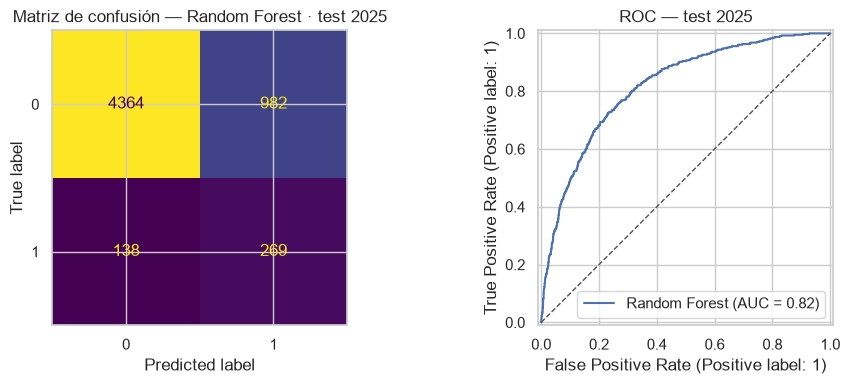

,importancia
log_ipcm,0.274606
edad,0.221095
condicion_actividad_Inactivo,0.135390
condicion_actividad_Ocupado,0.065638
zona_Urbana,0.030281
zona_Rural,0.027441
pobreza_No pobre,0.022869
sexo_Mujer,0.018075
sexo_Hombre,0.017654
condicion_actividad_Desocupado,0.016272


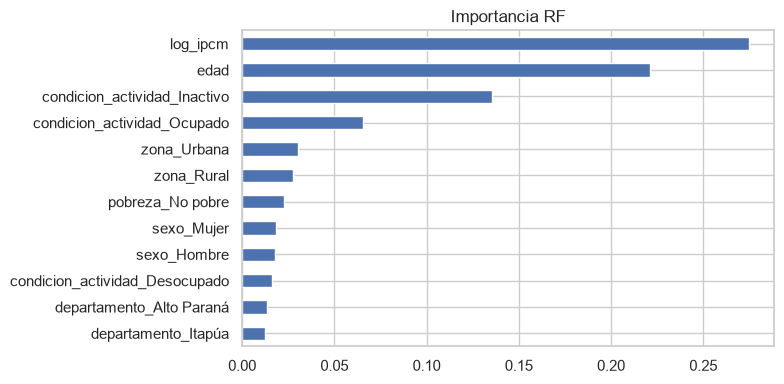

tipo,FN,FP,OK
zona,,,
Rural,0.025,0.250,0.725
Urbana,0.023,0.105,0.872


,FN,positivos,tasa_FN
edad,,,
12.0,9,9,1.000000
13.0,7,18,0.388889
14.0,28,46,0.608696
15.0,35,69,0.507246
16.0,23,88,0.261364
17.0,36,177,0.203390


In [4]:
model = fitted[BEST_NAME]
umbral = thresholds[BEST_NAME]
proba = model.predict_proba(X_te)[:, 1]
pred = (proba >= umbral).astype(int)
print(resumen[(resumen.modelo == BEST_NAME) & (resumen.split == 'test')].T)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay.from_predictions(y_te, pred, ax=axes[0], colorbar=False)
axes[0].set_title(f'Matriz de confusión — {BEST_NAME} · test 2025')
RocCurveDisplay.from_predictions(y_te, proba, ax=axes[1], name=BEST_NAME)
axes[1].plot([0, 1], [0, 1], '--', color='#52514e', lw=1)
axes[1].set_title('ROC — test 2025')
fig.tight_layout()
fig.savefig(DIR_FIG / 'F3_notebook_eval.png')
plt.show()

# Importancia RF (siempre disponible; útil aunque el best sea otro)
prep = fitted['Random Forest'].named_steps['prep']
from src.fase3_helpers import FEATURES_NUM, FEATURES_CAT
names = list(FEATURES_NUM) + list(
    prep.named_transformers_['cat'].get_feature_names_out(FEATURES_CAT)
)
imp = pd.Series(
    fitted['Random Forest'].named_steps['clf'].feature_importances_, index=names
).sort_values(ascending=False)
display(imp.head(12).to_frame('importancia'))
imp.head(12).iloc[::-1].plot(kind='barh', figsize=(8, 4), title='Importancia RF')
plt.tight_layout()
plt.savefig(DIR_FIG / 'F3_notebook_imp.png')
plt.show()

err = test_df.copy()
err['proba'], err['pred'] = proba, pred
err['tipo'] = np.where(
    (err[TARGET] == 1) & (err.pred == 0), 'FN',
    np.where((err[TARGET] == 0) & (err.pred == 1), 'FP', 'OK'),
)
display(pd.crosstab(err['zona'], err['tipo'], normalize='index').round(3))
display(
    err[err.tipo == 'FN'].groupby('edad').size().rename('FN').to_frame().join(
        err[err[TARGET] == 1].groupby('edad').size().rename('positivos')
    ).assign(tasa_FN=lambda d: d.FN / d.positivos)
)


## 6. Predicción manual — ingresar X y ver el Y de cada modelo

Editá las variables de abajo y volvé a ejecutar la celda. Cada modelo responde con su chance
y con `Y_predicho` (0 = asiste, 1 = no asiste).


In [5]:
# >>> EDITÁ ESTOS VALORES <<<
edad = 16
zona = 'Rural'                 # 'Urbana' o 'Rural'
departamento = 'San Pedro'     # ver lista impresa abajo
sexo = 'Hombre'                # 'Hombre' o 'Mujer'
condicion_actividad = 'Ocupado'  # 'Ocupado' | 'Desocupado' | 'Inactivo'
pobreza = 'Extrema'              # 'Extrema' | 'No extrema' | 'No pobre'
ipcm = 400_000                   # ingreso per cápita del hogar (Gs)

# Esta celda funciona sola (no hace falta correr todo el notebook antes)
import sys
from pathlib import Path
from importlib import reload
import joblib

_raiz = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(_raiz))

import src.fase3_helpers as _f3
_f3 = reload(_f3)  # evita usar una versión vieja en memoria del kernel
make_feature_frame = _f3.make_feature_frame
predict_with_models = _f3.predict_with_models
ZONAS_VALIDAS = _f3.ZONAS_VALIDAS
SEXOS_VALIDOS = _f3.SEXOS_VALIDOS
DEPARTAMENTOS_VALIDOS = _f3.DEPARTAMENTOS_VALIDOS
CONDICIONES_ACTIVIDAD = _f3.CONDICIONES_ACTIVIDAD
POBREZAS_VALIDAS = _f3.POBREZAS_VALIDAS

_dir_mod = _raiz / 'output' / 'modelos'
_bundle = joblib.load(_dir_mod / 'fase3_modelos_todos.joblib')
fitted = _bundle['fitted']
thresholds = _bundle['thresholds']
BEST_NAME = _bundle.get('best_model', 'Logística')
print('(Modelos cargados desde fase3_modelos_todos.joblib)')

print('Zonas válidas:', ZONAS_VALIDAS)
print('Sexos válidos:', SEXOS_VALIDOS)
print('Departamentos válidos:', DEPARTAMENTOS_VALIDOS)
print('Condición de actividad:', CONDICIONES_ACTIVIDAD)
print('Pobreza:', POBREZAS_VALIDAS)

X_manual = make_feature_frame(
    edad, zona, departamento, sexo,
    condicion_actividad=condicion_actividad, pobreza=pobreza, ipcm=ipcm,
)
print('\nX ingresado:')
display(X_manual)

tabla_manual = predict_with_models(X_manual, fitted, thresholds)
cols = ['modelo', 'chance_no_asiste', 'umbral', 'Y_predicho', 'etiqueta']
display(tabla_manual[cols])
print('Modelo oficial del proyecto:', BEST_NAME,
      '→', tabla_manual.loc[tabla_manual.modelo == BEST_NAME, 'etiqueta'].iloc[0])


(Modelos cargados desde fase3_modelos_todos.joblib)
Zonas válidas: ('Urbana', 'Rural')
Sexos válidos: ('Hombre', 'Mujer')
Departamentos válidos: ('Alto Paraná', 'Amambay', 'Caaguazú', 'Caazapá', 'Canindeyú', 'Capital', 'Central', 'Concepción', 'Cordillera', 'Guairá', 'Itapúa', 'Misiones', 'Paraguarí', 'Presidente Hayes', 'San Pedro', 'Ñeembucú')
Condición de actividad: ('Ocupado', 'Desocupado', 'Inactivo')
Pobreza: ('Extrema', 'No extrema', 'No pobre')

X ingresado:


,edad,log_ipcm,zona,departamento,sexo,condicion_actividad,pobreza
0,16.0,12.899222,Rural,San Pedro,Hombre,Ocupado,Extrema


,modelo,chance_no_asiste,umbral,Y_predicho,etiqueta
0,Línea base (mayoritaria),0.0000,0.500,0,asiste
1,Logística,0.9084,0.525,1,no asiste
2,Random Forest,0.7028,0.400,1,no asiste
3,HistGradientBoosting,0.8159,0.550,1,no asiste


Modelo oficial del proyecto: Random Forest → no asiste


## 7. Serialización

El modelo final, el umbral y el bundle con todos los modelos se guardan para reutilizar
(`scripts/infer_fase3.py` o esta misma sección sin reentrenar).


In [6]:
bundle = {'pipeline': model, 'threshold': umbral, 'model_name': BEST_NAME,
          'features': FEATURE_COLS, 'target': TARGET}
joblib.dump(bundle, DIR_MOD/'fase3_modelo_final.joblib')
joblib.dump({'fitted': fitted, 'thresholds': thresholds, 'features': FEATURE_COLS,
             'target': TARGET, 'best_model': BEST_NAME, 'cv_f1': CV_F1},
            DIR_MOD/'fase3_modelos_todos.joblib')
meta = {'best_model': BEST_NAME, 'umbral': umbral, 'features': FEATURE_COLS, 'target': TARGET,
        'test_year': TEST_YEAR, 'seed': SEMILLA, 'best_params': BEST, 'cv_f1': CV_F1}
(DIR_MOD/'fase3_modelo_meta.json').write_text(
    json.dumps(meta, indent=2, ensure_ascii=False, default=str), encoding='utf-8'
)
resumen.to_csv(DIR_TAB/'fase3_metricas.csv', index=False, encoding='utf-8-sig')
print('Guardado:', DIR_MOD/'fase3_modelo_final.joblib')
print('Guardado:', DIR_MOD/'fase3_modelos_todos.joblib')


Guardado: /Users/ivanparedesozuna/Developer/proyecto-ds-inasistencia-py/output/modelos/fase3_modelo_final.joblib
Guardado: /Users/ivanparedesozuna/Developer/proyecto-ds-inasistencia-py/output/modelos/fase3_modelos_todos.joblib


## 8. Conclusión

- La línea base mayoritaria no detecta inasistencia (F1 ≈ 0); los tres modelos la superan en F1/AUC.
- Los hiperparámetros se eligen por CV temporal **dentro de train**; el test 2025 solo se mira al final.
- Las features económicas (actividad, pobreza, IPCM) aportan señal adicional al bloque demográfico.
- Uso legítimo: priorización; no sanción individual. Límites: sin distancia a la escuela, sin Chaco,
  un solo año de prueba, sin pesos de diseño DGEEC.
